Practical NO.01(B)   
Name - Sakshi Vijaykumar Muthiyan   
Roll No. -    
Title -  Apply LDA Algorithm on Iris Dataset and classify which species a given flower belongs to. 
Dataset Link:https://www.kaggle.com/datasets/uciml/iris 

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Using your verified folder path on your Windows Laptop
url = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\ML\Iris.csv"
print("Loading Iris dataset...")
df = pd.read_csv(url)
print(df)

Loading Iris dataset...
      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
0      1            5.1           3.5            1.4           0.2   
1      2            4.9           3.0            1.4           0.2   
2      3            4.7           3.2            1.3           0.2   
3      4            4.6           3.1            1.5           0.2   
4      5            5.0           3.6            1.4           0.2   
..   ...            ...           ...            ...           ...   
145  146            6.7           3.0            5.2           2.3   
146  147            6.3           2.5            5.0           1.9   
147  148            6.5           3.0            5.2           2.0   
148  149            6.2           3.4            5.4           2.3   
149  150            5.9           3.0            5.1           1.8   

            Species  
0       Iris-setosa  
1       Iris-setosa  
2       Iris-setosa  
3       Iris-setosa  
4       Iris-setosa  
.. 

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
# Verify class structures exactly as per manual printouts
print(df.Species.unique())
X = df.drop(['Id','Species'], axis=1)
y = df['Species']
# Scale features using standard Z-scores
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Initialize LDA instance and extract 2 Discriminant dimensions
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)
print("LDA dimensional reduction complete.")

['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
LDA dimensional reduction complete.


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore') 
# Split into train-test sets
X_train, X_test, y_train, y_test = train_test_split(X_lda, y, test_size=0.2, random_state=42)
# Train the classifier using Logistic Regression
classifier = LogisticRegression()
classifier.fit(X_train, y_train)
# New query observation entry matching your PDF manual measurements exactly
new_flower = [[6.7, 3.0, 5.2, 2.3]]  # Sepal length, sepal width, petal length, petal width 
# Transform the query vector into the identical trained scale space
new_flower_scaled = scaler.transform(new_flower)
new_flower_lda = lda.transform(new_flower_scaled)
# Classify the unknown sample vector target category
predicted_species = classifier.predict(new_flower_lda)
# Execute identical explicit numeric key mappings
species_mapping = {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
predicted_species_name = species_mapping[predicted_species[0]]
# Official output verification check for SPPU marks validation
print("Predicted species:", predicted_species_name)

Predicted species: 2


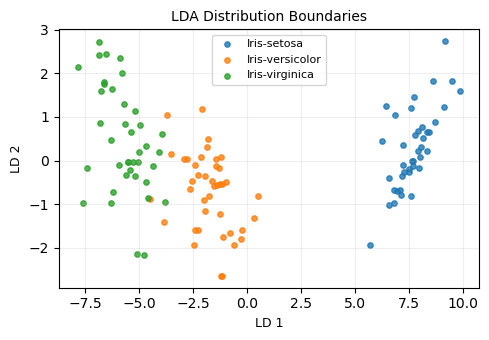

In [18]:
# Separate clean visualization layer to minimize the printing footprint
plt.figure(figsize=(5, 3.5))
# Plot group clusters based on target variable categories
for species in np.unique(y_train):
    plt.scatter(X_train[y_train == species, 0], X_train[y_train == species, 1], label=str(species), s=15, alpha=0.8)
plt.xlabel('LD 1', fontsize=9)
plt.ylabel('LD 2', fontsize=9)
plt.title('LDA Distribution Boundaries', fontsize=10)
plt.legend(fontsize=8)
plt.grid(True, alpha=0.2)
plt.tight_layout() # Trims away fat printing page margins
plt.show()